# Supervised MPNet fine-tuning pilot

Experiment log. Requires an **A100 GPU**. Compare a frozen MPNet encoder with the same encoder updated through a linear classification head, using three training seeds. This notebook contains no results until executed.

Upload `supervised_pilot_inputs.tar.gz` to `/content` before running. The CLI upload command is documented below.

## Context & Methods

256 training pages (128 per class), 192 validation pages (96 per class), and 447 fresh holdout pages (223 attacks, 224 non-injections). Raw HTML is unchanged and every token is covered by overlapping windows. A page receives one max-pooled score and one binary cross-entropy loss; no labels are assigned to individual chunks. Both arms use the same head initialization and page order for each seed.

At most two epochs; validation selects the epoch and threshold. The exploratory empirical false-positive budget is 5% (at most four errors among 96 validation negatives). All six models are frozen before any holdout inference.

### Key Assumptions

BrowseSafe labels come from its generation pipeline. A bounded label review quarantined training page 1567 without relabeling it. Labels on remaining pages are not independently verified. Lexical filtering reduces overlap but cannot establish independence of unknown website families. Max pooling cannot resolve interactions across distant windows. The final holdout is BrowseSafe-only and is consumed once evaluated.

Source: [BrowseSafe-Bench](https://huggingface.co/datasets/perplexity-ai/browsesafe-bench), revision `b506fb5bc7fd4472c8738055a67a0ef6406afdc9`. Full protocol and source hashes are in the input bundle.

### 1. Install the pinned environment

In [ ]:
import os, subprocess, sys
from pathlib import Path
os.environ.update(USE_TF='0', USE_FLAX='0', WANDB_MODE='disabled', TOKENIZERS_PARALLELISM='false')
packages = ['torch==2.9.1','sentence-transformers==5.1.2','transformers==4.57.3','datasets==4.4.1','xgboost==3.1.2','scikit-learn==1.7.2','numpy==2.3.5','scipy==1.16.3','beautifulsoup4==4.14.2','accelerate==1.11.0']
for command in [[sys.executable,'-m','pip','uninstall','-y','torchvision','torchaudio'], [sys.executable,'-m','pip','install','-q'] + packages]:
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as process:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait():
            raise RuntimeError('Environment setup failed')
print('Pinned environment installed. Model training uses fresh Python subprocesses.')


Found existing installation: torchvision 0.26.0+cu128


Uninstalling torchvision-0.26.0+cu128:


  Successfully uninstalled torchvision-0.26.0+cu128


Found existing installation: torchaudio 2.11.0+cu128


Uninstalling torchaudio-2.11.0+cu128:


...

gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.10.0 which is incompatible.


numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.3.5 which is incompatible.


diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


Pinned environment installed. Model training uses fresh Python subprocesses.


### 2. Verify the requested A100

In [ ]:
import subprocess, sys, json
code = "import torch,json; assert torch.cuda.is_available() and 'A100' in torch.cuda.get_device_name(); print(json.dumps({'gpu':torch.cuda.get_device_name(),'memory_GiB':torch.cuda.get_device_properties(0).total_memory/2**30}))"
print(subprocess.check_output([sys.executable,'-c',code],text=True))


{"gpu": "NVIDIA A100-SXM4-40GB", "memory_GiB": 39.4935302734375}



## Data
### 3. Verify and unpack the frozen inputs

In [ ]:
import tarfile, hashlib, json
from pathlib import Path
archive = Path('/content/supervised_pilot_inputs.tar.gz')
assert hashlib.sha256(archive.read_bytes()).hexdigest() == '7b5011d51c5532556efb9730289f8351602dcc7c5e035b825a27df644b647e65'
output = Path('/content/mpnet_supervised_pilot')
if not output.exists():
    with tarfile.open(archive) as bundle:
        bundle.extractall('/content', filter='data')
protocol = json.loads((output / 'protocol.json').read_text())
for name, expected in protocol['files'].items():
    assert hashlib.sha256((output/name).read_bytes()).hexdigest() == expected, name
print('Frozen inputs:', protocol['counts'])
print('Full HTML windows:', protocol['windows'])
print('Frozen at:', protocol['frozen_at'])


Frozen inputs: {'train': {'1': 128, '0': 128}, 'validation': {'0': 96, '1': 96}, 'holdout': {'0': 224, '1': 223}}
Full HTML windows: {'train': 18409, 'validation': 14823, 'holdout': 34189}
Frozen at: 2026-09-11T06:04:18.486473+00:00


### 4. Fit both arms across three seeds
This stage uses training and validation only.

In [ ]:
import subprocess, sys, os
command = [sys.executable,'-u',str(output/'supervised_pilot.py'),'train','--output',str(output)]
with Path('/content/supervised_train.log').open('w') as log:
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=dict(os.environ, USE_TF='0',USE_FLAX='0',WANDB_MODE='disabled')) as process:
        for line in process.stdout:
            log.write(line); log.flush()
            print(line,end='',flush=True)
        if process.wait():
            raise RuntimeError('train' + ' failed; do not proceed with later stages')


CUDA VERIFIED {"recorded_at": "2026-09-11T06:13:44.089533+00:00", "gpu": "NVIDIA A100-SXM4-40GB", "gpu_bytes": 42405855232, "packages": {"torch": "2.9.1", "sentence-transformers": "5.1.2", "transformers": "4.57.3", "numpy": "2.3.5", "scikit-learn": "1.7.2"}}


You're using a MPNetTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Encoding pages 1/256 (1s)


Encoding pages 33/256 (5s)


Encoding pages 65/256 (8s)


...

Encoding pages 97/192 (13s)


Encoding pages 129/192 (17s)


Encoding pages 161/192 (21s)


VALIDATION finetuned_73 2 {"n": 192, "tp": 44, "tn": 93, "fp": 3, "fn": 52, "accuracy": {"value": 0.7135416666666666, "nominal_wilson_95": [0.6458953147975586, 0.7728107165697651]}, "recall": {"value": 0.4583333333333333, "nominal_wilson_95": [0.36218849483208426, 0.5576844708227221]}, "fpr": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "threshold": 0.5627574920654297, "roc_auc": 0.8393012152777778, "average_precision": 0.8661599179422188, "balanced_accuracy": 0.7135416666666666}


ALL SIX MODELS FROZEN; holdout has not been scored


### 5. Evaluate the fresh holdout
This refuses to run until all six models and thresholds are frozen.

In [ ]:
import subprocess, sys, os
command = [sys.executable,'-u',str(output/'supervised_pilot.py'),'evaluate','--output',str(output)]
with Path('/content/supervised_evaluate.log').open('w') as log:
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=dict(os.environ, USE_TF='0',USE_FLAX='0',WANDB_MODE='disabled')) as process:
        for line in process.stdout:
            log.write(line); log.flush()
            print(line,end='',flush=True)
        if process.wait():
            raise RuntimeError('evaluate' + ' failed; do not proceed with later stages')


You're using a MPNetTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Encoding pages 1/447 (1s)


Encoding pages 33/447 (6s)


Encoding pages 65/447 (11s)


Encoding pages 97/447 (16s)


...

Encoding pages 321/447 (43s)


Encoding pages 353/447 (46s)


Encoding pages 385/447 (51s)


Encoding pages 417/447 (55s)


HOLDOUT finetuned_73 {"n": 447, "tp": 114, "tn": 223, "fp": 1, "fn": 109, "accuracy": {"value": 0.7539149888143176, "nominal_wilson_95": [0.7119332386995023, 0.7915697013224379]}, "recall": {"value": 0.5112107623318386, "nominal_wilson_95": [0.4459705782344384, 0.5760712479202429]}, "fpr": {"value": 0.004464285714285714, "nominal_wilson_95": [0.0007884912109385606, 0.024849769933145915]}, "threshold": 0.5627574920654297, "roc_auc": 0.8584240871236387, "average_precision": 0.8912372923899088, "balanced_accuracy": 0.7533732383087764}


## Results
### 6. Compare every seed

Completed: 2026-09-11T06:25:55.917079+00:00
frozen_17        AUC=0.5316 recall=7.17% FPR=6.25%
finetuned_17     AUC=0.8353 recall=61.88% FPR=2.23%
frozen_42        AUC=0.5264 recall=5.38% FPR=4.02%
finetuned_42     AUC=0.4668 recall=10.31% FPR=8.48%
frozen_73        AUC=0.5158 recall=5.83% FPR=5.36%
finetuned_73     AUC=0.8584 recall=51.12% FPR=0.45%


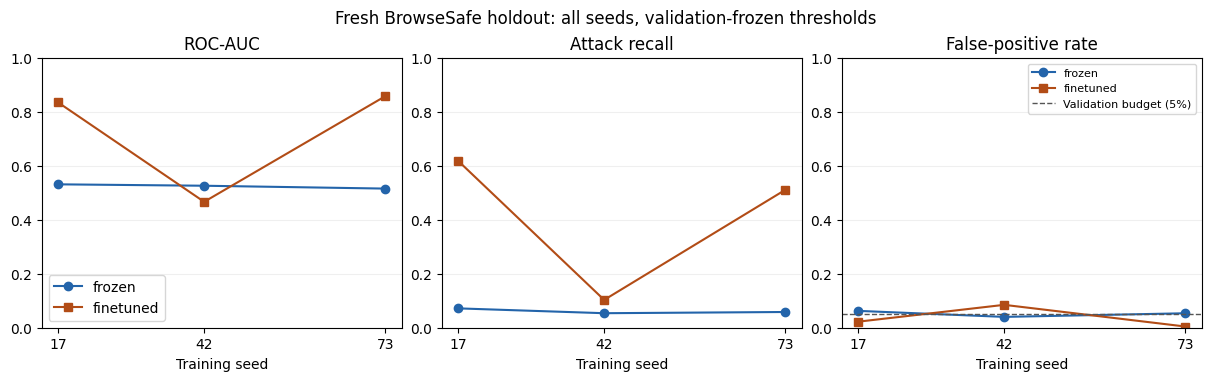

Research pilot; machine-generated labels and unknown template relationships limit conclusions.


In [ ]:
import json
import matplotlib.pyplot as plt
result = json.loads((output/'holdout_results.json').read_text())
print('Completed:',result['completed_at'])
for name, r in result['summaries'].items():
    print(f"{name:16s} AUC={r['roc_auc']:.4f} recall={r['recall']['value']:.2%} FPR={r['fpr']['value']:.2%}")
fig, axes = plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
for ax, metric, title in zip(axes, ['roc_auc','recall','fpr'], ['ROC-AUC','Attack recall','False-positive rate']):
    for arm,color,marker in [('frozen','#2364aa','o'),('finetuned','#b24c16','s')]:
        values=[result['summaries'][f'{arm}_{seed}'][metric] for seed in [17,42,73]]
        values=[v['value'] if isinstance(v,dict) else v for v in values]
        ax.plot([17,42,73],values,marker=marker,color=color,label=arm)
    ax.set(title=title,xlabel='Training seed',xticks=[17,42,73],ylim=(0,1))
    ax.grid(axis='y',alpha=.2)
axes[2].axhline(.05,color='#555555',ls='--',lw=1,label='Validation budget (5%)')
axes[0].legend(); axes[2].legend(fontsize=8)
fig.suptitle('Fresh BrowseSafe holdout: all seeds, validation-frozen thresholds')
fig.savefig(output/'comparison.png',dpi=160)
plt.show()
print('Research pilot; machine-generated labels and unknown template relationships limit conclusions.')


## Takeaways
Interpret the actual held-out false-positive rates alongside recall. A validation constraint is not a guarantee on new inputs. Retain the historical baseline and report negative results. No model is deployed by this notebook.

### 7. Preserve the full evidence and checkpoints

In [ ]:
import tarfile, hashlib
from pathlib import Path
assert (output/'holdout_results.json').exists()
archive=Path('/content/supervised_pilot_complete.tar')
with tarfile.open(archive,'w') as bundle:
    bundle.add(output,arcname='mpnet_supervised_pilot')
    for stage in ['train','evaluate']:
        bundle.add(Path('/content')/f'supervised_{stage}.log',arcname=f'supervised_{stage}.log')
with archive.open('rb') as stream:
    checksum=hashlib.file_digest(stream,'sha256').hexdigest()
print('Complete results and checkpoints:',str(archive),'bytes:',archive.stat().st_size,'SHA256:',checksum)


Complete results and checkpoints: /content/supervised_pilot_complete.tar bytes: 2187632640 SHA256: 5ad07e2a7f71618715eeb94edc0b14a3a201cfbc0b173ad60fd37fca2d419ec1


Retrieve `/content/supervised_pilot_complete.tar` before releasing the runtime.

```sh
colab upload -s mpnet-supervised-a100 notebooks/supervised_pilot_inputs.tar.gz /content/supervised_pilot_inputs.tar.gz
colab exec -s mpnet-supervised-a100 --timeout 14400 -f notebooks/colab_supervised_pilot.ipynb
colab download -s mpnet-supervised-a100 /content/supervised_pilot_complete.tar results/supervised_pilot_20260911/supervised_pilot_complete.tar
```